# 2 · Forex: how currencies move together, and whether pair leftovers pull back

**Data:** HistData hourly prices 2010 – 2026 for 9 currencies + gold + silver, each priced in US dollars (USDxxx pairs inverted), and 23 cross pairs (EURGBP, AUDNZD, EURJPY, …).

**Steps**
1. Correlation heatmap of daily returns.
2. PCA on standardised hourly returns (= PCA on the correlation matrix, same as `StandardScaler` + PCA): share of each factor (scree) and loadings.
3. For each cross, the PCA leftover is *euro's own move − pound's own move* (for EURGBP). The daily model (120-day window, refit every 5 days, 3 factors removed, past data only) gives an out-of-sample leftover; its **variance ratio** tells whether it pulls back, compared with gold/silver's.
4. Typical distance of each cross from its own 1-year average.
5. For reference, the result of trading the pullback (details in `backtesting/04`).

In [1]:
import sys
sys.path.insert(0, "../src")   # shared code lives in src/; data in ../data (see README)
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200)

Data: HistData daily candles (17:00 New York close), 2010-01-04 -> 2026-10-16

1. Correlation of daily returns (each currency in USD):
      EUR   GBP   AUD   NZD   CAD   CHF   JPY   NOK   SEK   XAU   XAG
EUR  1.00  0.63  0.56  0.57  0.48  0.62  0.35  0.68  0.79  0.32  0.31
GBP  0.63  1.00  0.56  0.55  0.48  0.41  0.26  0.58  0.59  0.28  0.30
AUD  0.56  0.56  1.00  0.83  0.70  0.37  0.22  0.67  0.63  0.36  0.42
NZD  0.57  0.55  0.83  1.00  0.63  0.40  0.28  0.63  0.61  0.36  0.39
CAD  0.48  0.48  0.70  0.63  1.00  0.30  0.10  0.62  0.54  0.27  0.34
CHF  0.62  0.41  0.37  0.40  0.30  1.00  0.41  0.43  0.50  0.35  0.26
JPY  0.35  0.26  0.22  0.28  0.10  0.41  1.00  0.21  0.26  0.33  0.19
NOK  0.68  0.58  0.67  0.63  0.62  0.43  0.21  1.00  0.77  0.32  0.37
SEK  0.79  0.59  0.63  0.61  0.54  0.50  0.26  0.77  1.00  0.32  0.35
XAU  0.32  0.28  0.36  0.36  0.27  0.35  0.33  0.32  0.32  1.00  0.78
XAG  0.31  0.30  0.42  0.39  0.34  0.26  0.19  0.37  0.35  0.78  1.00



2. PCA, hourly 2010-2026: variance explained %
   PC1 49  PC2 13  PC3 10  PC4 7  PC5 5  PC6 4  PC7 4  PC8 3  PC9 2  PC10 2  PC11 2   (first 3 together: 72%)
loadings of the first 3 factors:
      EUR   GBP   AUD   NZD   CAD   CHF   JPY   NOK   SEK   XAU   XAG
PC1  0.36  0.31  0.35  0.34  0.30  0.29  0.17  0.34  0.35  0.23  0.23
PC2  0.12  0.14  0.13  0.11  0.17 -0.04 -0.29  0.19  0.18 -0.64 -0.59
PC3 -0.25 -0.06  0.30  0.25  0.34 -0.46 -0.58 -0.01 -0.13  0.13  0.28



3. Variance ratio of the PCA leftover, out-of-sample.  <1 comes back,  >=1 drifts/trends
             5 days  10 days  20 days
EURSEK         0.84     0.79     0.81
EURCHF         0.80     0.83     0.98
EURCAD         0.90     0.84     0.82
GBPCHF         0.91     0.86     0.83
AUDCAD         0.90     0.86     0.82
AUDCHF         0.87     0.89     0.94
EURNOK         0.93     0.89     0.89
CHFJPY         0.88     0.90     0.96
CADCHF         0.91     0.95     0.98
GBPCAD         0.95     0.95     0.74
CADJPY         0.95     0.95     0.94
NZDCHF         0.87     0.95     0.99
AUDJPY         0.99     0.98     1.09
EURGBP         1.02     0.99     0.91
NZDCAD         0.94     1.00     1.06
EURJPY         0.95     1.01     1.03
EURAUD         0.98     1.02     0.98
EURNZD         0.98     1.04     1.10
GBPJPY         1.07     1.06     0.87
GBPNZD         1.06     1.11     1.08
GBPAUD         1.05     1.12     1.08
NZDJPY         1.05     1.13     1.30
AUDNZD         1.06     1.14     1.2


4. Typical distance from its own 1-year average (median, %):
   EURCHF 1.4  AUDNZD 1.7  EURSEK 1.8  GBPCAD 1.9  NZDCAD 2.0  EURNOK 2.1  EURGBP 2.2  AUDCAD 2.3  GBPNZD 2.5  EURNZD 2.6  GBPCHF 2.6  EURCAD 2.6  EURAUD 2.7  CADCHF 2.8  AUDCHF 3.0  NZDCHF 3.0  GBPAUD 3.2  CADJPY 3.4  CHFJPY 3.7  AUDJPY 3.7  GBPJPY 3.8  NZDJPY 3.9  EURJPY 3.9  GOLD/SILVER 5.2



5. Daily residual strategy, 13 crosses, swap-free, costs = Vantage spreads + commission:
       trades  win_pct  hold_days  return % period
entry                                             
2010       16     56.2       13.6       6.2  train
2011       32     62.5       12.8       7.6  train
2012       14     50.0       13.8       1.6  train
2013       37     62.2        7.6       4.6  train
2014       34     79.4        9.4      14.2  train
2015       29     69.0        9.6      16.5  train
2016       31     64.5       11.4       9.4  train
2017       32     78.1       10.8      18.3  train
2018       24     50.0       16.3      -3.5  train
2019       25     56.0       16.1      -2.2   test
2020       33     60.6        9.0       9.4   test
2021       34     55.9       15.5      -5.8   test
2022       33     63.6        7.9       1.8   test
2023       27     74.1        7.2       6.5   test
2024       22     72.7        9.9       5.7   test
2025       37     70.3        9.6       5.2


charts in G:\pca-forex-analysis\data\forex


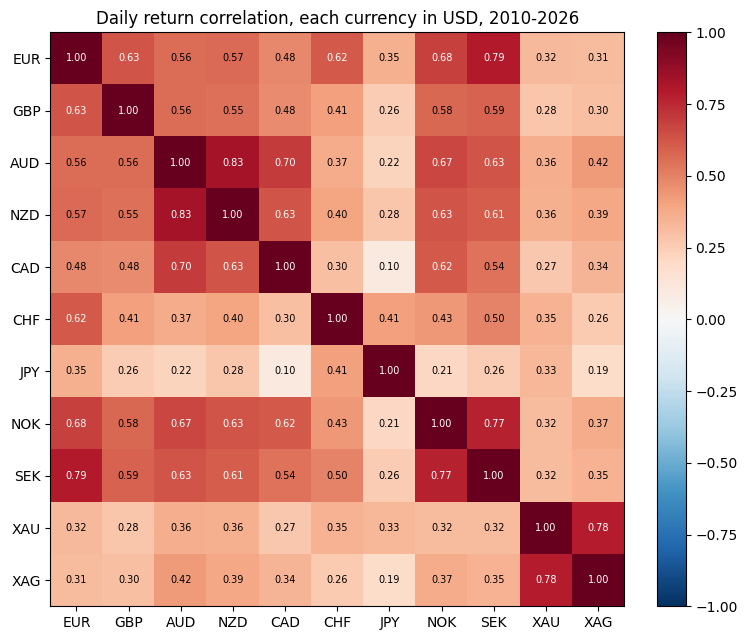

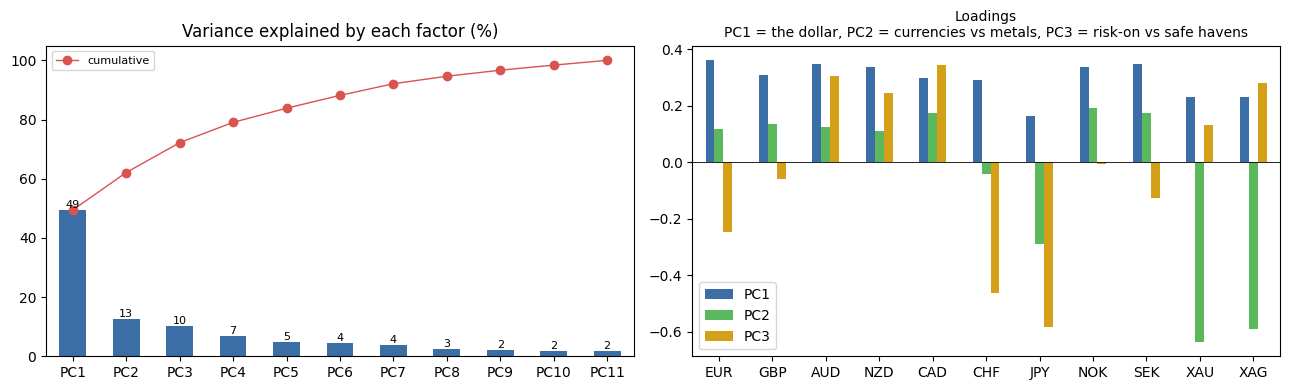

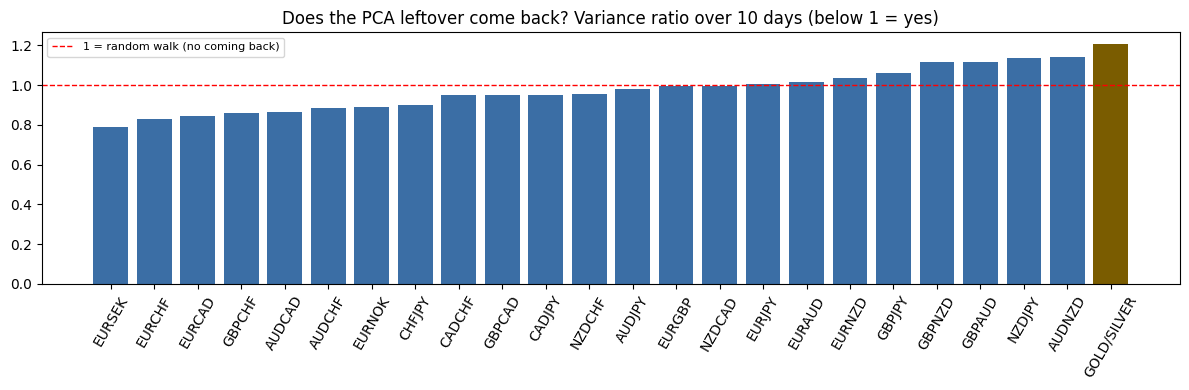

<Figure size 640x480 with 0 Axes>

In [2]:
%run ../src/forex_analysis.py

### What this shows
* All currencies are positively correlated because the dollar moves them together; JPY is the least connected (safe haven).
* **Three forces explain 72% of all movement:** PC1 49% = the dollar against everything, PC2 13% = currencies vs metals, PC3 10% = risk-on currencies (AUD, NZD, CAD) vs safe havens (JPY, CHF).
* **15 of 23 cross leftovers have a variance ratio below 1** (EURSEK 0.79 strongest); **gold/silver is the worst of all 24 (1.20).**
* Crosses stay 1.4 – 3.9% from their 1-year average; gold/silver 5.2%.

**Conclusion:** after PCA removes the common forces, most forex cross leftovers pull back; gold/silver does not.